# ¿Qué pierde un predictor que solamente recibe R0?

**Pregunta:** ¿Puede el pequeño predictor de regresión resumir el pico de cualquier escenario SIR a partir de su razón reproductiva, y cómo cambian esa interpretación el entrenamiento, la evaluación reservada y las condiciones iniciales omitidas?

- **Nivel:** 2, el método en la práctica
- **Requisitos:** las dos lecciones anteriores de umbral y tamaño final, y la lección del motor
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Sigue un insumo desde la admisión y las características reales hasta un modelo entrenado temporalmente, distinguiendo error de ajuste, error reservado e información perdida. El ejercicio trata la regresión existente de cuatro términos y su respaldo analítico. No propone otro método epidémico ni entrena un pronóstico o reemplaza el modelo publicado. La pregunta central es si una interfaz cómoda de un solo número conserva la información suficiente para la cantidad que el lector cree obtener.

## Preparación

Usa el entorno exacto de los notebooks:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

La plantilla no publica una distribución Python de sus métodos. Importa los módulos existentes de `data-pipeline` por su ruta en el repositorio. Define `CAOS_TEMP_ROOT` como directorio externo antes de usar el ejecutor. El contexto temporal elimina solamente el modelo del ejemplo que posee; nunca escribe en `models/` canónico. La preparación lee el esquema versionado. La celda Datos selecciona los casos del registro y carga el modelo versionado sin modificar ninguno.

In [1]:
# Mantener el ajuste temporal fuera del repositorio y utilizar las APIs existentes.
import importlib.metadata as md
import json
import os
import sys
from dataclasses import replace
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline import registry
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import is_valid_bundle, peak_frac
from pipeline.stages import evaluate, feature_extraction, infer, preprocess, train

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))
bundle_schema = json.loads((ROOT / "docs/contracts/schemas/surrogate-model.schema.json").read_text(encoding="utf-8"))


numpy 2.4.6
matplotlib 3.11.2


## Datos

El propietario es este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE; su licencia MIT cubre ejemplos sintéticos construidos. No hay observaciones de pacientes ni datos clínicos. Se leen `data/examples/params.csv`, `data/derived/manifests/index.json`, `models/surrogate.json` y `docs/contracts/schemas/surrogate-model.schema.json`. Los puntos de entrenamiento provienen del registro público, cuyos parámetros describen los mismos casos declarados en el índice. Los puntos reservados nuevos son perturbaciones deterministas del caso epidémico, identificadas separadamente en vez de presentarse como datos de campo.

El CSV incluye deliberadamente contacto negativo e infecciones iniciales excesivas. Preprocesarlo primero enseña el límite params-record: beta/gamma están en días inversos, N/I0 en personas y days es el horizonte. Las características aceptadas exponen r0, beta, gamma, logaritmo poblacional y fracción inicialmente infectada. El ajuste consumirá deliberadamente solamente r0.

In [2]:
# Admitir antes de calcular características, incluyendo filas fuente rechazadas.
released = train.load_released(ROOT / "models")
training = [case.params for case in registry.list_cases() if case.params.I0 > 0]
base = registry.get_case("EX02_epidemic").params
admission = preprocess.run(str(ROOT / "data/examples/params.csv"))
features = feature_extraction.run(admission.accepted)
print(f"{len(admission.accepted)} aceptados, {len(admission.rejected)} rechazados, "
      f"{len(admission.flagged)} advertidos")
for row in features:
    print(row.case_id, f"r0={row.r0:.2f}, log10(N)={row.n_scaled:.1f}, i0_frac={row.i0_frac:.5f}")
print("rechazados:", [row["case_id"] for row in admission.rejected])

2 aceptados, 2 rechazados, 0 advertidos
EX02_epidemic r0=2.75, log10(N)=5.0, i0_frac=0.00050
EX01_subcritical r0=0.72, log10(N)=5.0, i0_frac=0.00050
rechazados: ['bad_negbeta', 'bad_i0_gt_N']


## Método

La etapa de características conserva más información que la ranura del modelo. `FeatureRow` contiene tasas originales, escala poblacional y fracción infectada inicial, pero el entrenador construye su matriz a partir de la razón reproductiva escalar. Para la fila $j$, la salida $y_j$ es el máximo de infectados del motor dividido por su población durante el horizonte solicitado. El problema real de ajuste es

$$\widetilde r=\max(r,10^{-6}),\quad\phi(r)=(1,\widetilde r,\ln\widetilde r,1/\widetilde r),\quad X_{j,:}=\phi(r_j),\quad c^*=\operatorname*{argmin}_c\|Xc-y\|_2^2.$$

Columnas y objetivos son adimensionales; interpretar coeficientes exige respetar exactamente su orden. La API primaria de mínimos cuadrados de NumPy documenta minimización residual y convención de rango. Las cuatro columnas son una elección ilustrativa de la plantilla, no un descubrimiento científico aprendido ni una base demostrada óptima para epidemias. El entrenador existente llama a esa API; este notebook no reconstruye su matriz ni estima coeficientes por otra implementación.

La orquestación publicada entrena con casos no degenerados del registro y evalúa otra muestra sintética de veinte puntos con semilla. Esta lección utiliza el mismo entrenador público, pero una malla reservada diferente de seis puntos para hacer visible la distinción. Sus errores no reproducen ni sustituyen las métricas de los manifiestos. Excluir del ajuste el control exactamente sin infecciones forma parte de ese protocolo fuente y revela una limitación importante cuando después se pregunta por una población sin semilla.

El diseño real usa primero max(r0,1e-6), de modo que razones positivas menores que ese corte reciben las mismas características. La fórmula escrita incluye ahora ese dominio computacional exacto. El recorte no sustituye la admisión de entradas: el contrato de uso exige una razón positiva finita, y el comportamiento heredado del auxiliar con valores no admitidos no constituye una predicción válida.

In [3]:
# Ajustar casos declarados y reservar puntos de operación realmente diferentes.
train_r0 = [p.beta / p.gamma for p in training]
train_truth = [infer.run(p).peak_I / p.N for p in training]
held_r0 = [0.9, 1.5, 2.0, 3.5, 5.0, 7.0]
holdout = [replace(base, case_id=f"lesson_holdout_{k}", beta=r0 * base.gamma)
           for k, r0 in enumerate(held_r0)]
held_truth = [infer.run(p).peak_I / p.N for p in holdout]
print("R0 de ajuste:", [round(v, 2) for v in train_r0])
print("R0 reservados:", held_r0)
print("R0 compartidos:", sorted(set(train_r0).intersection(held_r0)))

R0 de ajuste: [0.72, 2.75, 6.0, 1.2]
R0 reservados: [0.9, 1.5, 2.0, 3.5, 5.0, 7.0]
R0 compartidos: []


Las listas de razones reproductivas impresas no comparten ningún valor. Se evita reutilizar directamente un punto de entrenamiento, pero no se obtiene una prueba representativa del mundo real. Ambos conjuntos todavía provienen de las mismas ecuaciones deterministas y comparten población, escala inicial de infección y horizontes mayormente parecidos. Hay cuatro coeficientes y cuatro casos de ajuste: residuos pequeños pueden reflejar interpolación en vez de generalización. La siguiente celda usa el entrenador existente en un directorio temporal externo, recupera el modelo mediante el lector publicado y muestra sus campos semánticos. También lee el modelo canónico sin modificarlo.

In [4]:
# Usar el entrenador real con un modelo temporal sin tocar el publicado.
with TemporaryDirectory(prefix="sir-lesson-", dir=os.environ["CAOS_TEMP_ROOT"]) as temporary:
    model = train.run(training, temporary)
    loaded = train.load_released(temporary)
    print("modelo válido:", is_valid_bundle(loaded))
print("campos requeridos:", bundle_schema["required"])
print("kind:", model["kind"], "basis:", model["basis"])
print("coeffs:", [round(value, 6) for value in model["coeffs"]])
print("modelo publicado válido:", is_valid_bundle(released))

modelo válido: True
campos requeridos: ['kind', 'basis', 'coeffs']
kind: linear-lstsq basis: ['1', 'r0', 'ln(r0)', '1/r0']
coeffs: [-0.607253, -0.071256, 0.823704, 0.669346]
modelo publicado válido: True


El contrato surrogate-model exige exactamente `kind`, `basis` y `coeffs`. El tipo es `linear-lstsq`; nombres y orden de la base deben corresponder a las cuatro columnas fijas; deben existir cuatro coeficientes finitos. `is_valid_bundle` es el predicado semántico del producto para esa forma, incluyendo rechazo de campos adicionales y tipos numéricos inválidos. Un modelo válido todavía puede predecir mal: esquema y admisión no establecen cobertura para otro uso. Que el lector devuelva un modelo tampoco demuestra que terminó un entrenamiento nuevo ni que la predicción tenga incertidumbre estadística.

Al inferir, el predictor público evalúa la expresión ajustada y la recorta al intervalo contractual:

$$\widehat p(r)=\min(1,\max(0,\phi(r)^\top c^*)),\qquad \operatorname{RMSE}=\sqrt{\frac1m\sum_{j=1}^m(\widehat p_j-y_j)^2}.$$

RMSE se expresa en fracción infectada. El evaluador también devuelve R cuadrado, comparando error cuadrático acumulado con variación alrededor de la media verdadera reservada, y cantidad de puntos. Devuelve cero para R cuadrado si las verdades no varían; esa convención no debe leerse como certificado general de desempeño. El error absoluto de fracción resulta más interpretable cerca de un pico subcrítico que dividir por una verdad casi nula.

In [5]:
# Evaluar la población reservada separada de los ejemplos que ajustan coeficientes.
metrics = evaluate.run(model, holdout)
predicted = [train.predict(model, value) for value in held_r0]
print("ajustado:", metrics)
print("procedencia:", evaluate.models_used(model))
for value, truth, prediction in zip(held_r0, held_truth, predicted):
    print(f"R0={value:.2f}, verdad={truth:.5f}, predicción={prediction:.5f}, residual={prediction-truth:+.5f}")

ajustado: {'surrogate_peakfrac_r2': 0.9997, 'surrogate_peakfrac_rmse': 0.00385, 'n_holdout': 6}
procedencia: {'surrogate-model': 'real'}
R0=0.90, verdad=0.00050, predicción=0.00000, residual=-0.00050
R0=1.50, verdad=0.06379, predicción=0.06608, residual=+0.00228
R0=2.00, verdad=0.15552, predicción=0.15586, residual=+0.00034
R0=3.50, verdad=0.36452, predicción=0.36650, residual=+0.00198
R0=5.00, verdad=0.49226, predicción=0.49604, residual=+0.00377
R0=7.00, verdad=0.60051, predicción=0.59243, residual=-0.00808


Los residuos reservados comparan predicciones con ejecuciones nuevas del motor en los puntos diferentes. Residuo positivo significa sobrestimar el pico del motor condicionado al horizonte, no sobrepredecir carga de enfermedad real. Los objetivos de entrenamiento conservan discretización Euler y error de muestreo. Un integrador más preciso cambiaría esas etiquetas, salvo actualizar entrenamiento y comparación conjuntamente. Para exponer el respaldo, en lugar de suponer que siempre hay modelo, llama al mismo evaluador con `None`. Usa el pico SIR analítico de semilla pequeña ya presentado y registra otra procedencia.

In [6]:
# Exponer el respaldo analítico con el mismo evaluador y la misma ranura.
baseline_metrics = evaluate.run(None, holdout)
baseline_predictions = [peak_frac(value) for value in held_r0]
print("baseline:", baseline_metrics)
print("procedencia:", evaluate.models_used(None))

baseline: {'surrogate_peakfrac_r2': 0.9975, 'surrogate_peakfrac_rmse': 0.01102, 'n_holdout': 6}
procedencia: {'surrogate-model': 'baseline'}


Respaldo y modelo ajustado comparten la ranura escalar de entrada y fracción de salida, permitiendo conservar el consumidor cuando falta un modelo publicado. Es sustitución de interfaz, no igualdad de supuestos. La base analítica supone infección inicial despreciable y un brote que alcanza su pico. El ajuste aproxima las etiquetas Euler finitas que vio al entrenar. Compararlos sobre puntos reservados idénticos expone significados distintos, sin convertir ninguno en método de pronóstico generalmente aceptado. La figura siguiente ubica entrenamiento, verdades nuevas y ambos predictores en un eje.

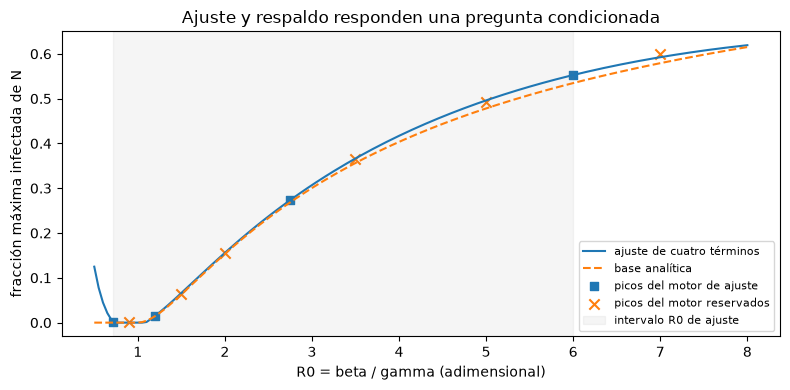

In [7]:
# Separar ajuste, verdades reservadas y ambos predictores en las mismas coordenadas.
comparison_grid = np.linspace(0.5, 8.0, 151)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(comparison_grid, [train.predict(model, value) for value in comparison_grid], label="ajuste de cuatro términos")
ax.plot(comparison_grid, [peak_frac(value) for value in comparison_grid], "--", label="base analítica")
ax.scatter(train_r0, train_truth, marker="s", label="picos del motor de ajuste")
ax.scatter(held_r0, held_truth, marker="x", s=55, label="picos del motor reservados")
ax.axvspan(min(train_r0), max(train_r0), alpha=0.08, color="grey", label="intervalo R0 de ajuste")
ax.set_xlabel("R0 = beta / gamma (adimensional)")
ax.set_ylabel("fracción máxima infectada de N")
ax.set_title("Ajuste y respaldo responden una pregunta condicionada")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los cuadrados de entrenamiento quedan cerca de la línea ajustada porque aportaron sus coeficientes. Las cruces representan otros puntos, incluyendo uno fuera de la mayor razón ajustada, y pueden desviarse aunque su esquema no cambie. El sombreado es únicamente el intervalo observado de entrenamiento, no una banda de confianza. La base sigue una relación analítica límite: diferir del ajuste puede reflejar supuestos iniciales o numéricos además de aproximación. Ninguna curva revela la fecha del pico. Extraer esa fecha de un modelo de una salida inventaría información que no devuelve.

### Sensibilidad: un R0 idéntico puede esconder condiciones incompatibles

Mantén beta/gamma fijo y cambia solamente infección inicial y horizonte de presentación. El motor recibe todos esos insumos, mientras `train.predict(model, r0)` no los ve. El mapa siguiente incluye un control exactamente sin semilla, un horizonte corto de diez días y una fracción inicial importante. Son sondeos construidos deliberadamente, no muestras adicionales de entrenamiento ni estimaciones repetidas de incertidumbre observacional. Como el modelo tampoco recibe inmunidad inicial, cambiarla exigiría transformar coherentemente entrada y definición del objetivo.

mismo R0=2.75, misma predicción=0.27345
fracciones máximas del motor:
[[0.      0.01391 0.29235 0.3557 ]
 [0.      0.27345 0.29235 0.3557 ]
 [0.      0.27345 0.29235 0.3557 ]]


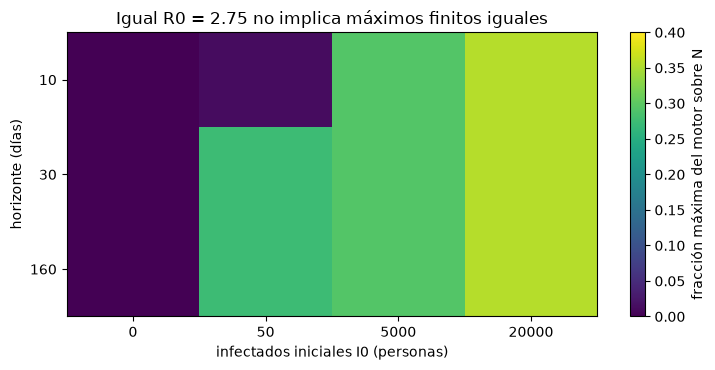

In [8]:
# La misma entrada escalar no distingue ausencia de semilla, brevedad y semilla grande.
initial = [0, 50, 5000, 20000]
horizons = [10, 30, 160]
alias_truth = np.array([[infer.run(replace(base, I0=first, days=days)).peak_I / base.N
                         for first in initial] for days in horizons])
same_prediction = train.predict(model, base.beta / base.gamma)
print(f"mismo R0={base.beta/base.gamma:.2f}, misma predicción={same_prediction:.5f}")
print("fracciones máximas del motor:")
print(np.round(alias_truth, 5))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
image = ax.imshow(alias_truth, aspect="auto", vmin=0, vmax=max(0.4, alias_truth.max()))
ax.set_xticks(range(len(initial)), initial)
ax.set_yticks(range(len(horizons)), horizons)
ax.set_xlabel("infectados iniciales I0 (personas)")
ax.set_ylabel("horizonte (días)")
ax.set_title("Igual R0 = 2.75 no implica máximos finitos iguales")
fig.colorbar(image, ax=ax, label="fracción máxima del motor sobre N")
fig.tight_layout()
plt.show()

La columna sin semilla permanece en cero porque el motor determinista carece de fuente infecciosa. Las columnas con semilla y los horizontes distintos producen otras fracciones máximas, pese al único valor idéntico del predictor impreso sobre la matriz. Optimizar coeficientes no permite asignar varias respuestas correctas diferentes a una misma entrada escalar. Es pérdida de información identificadora, no solamente entrenamiento insuficiente o regresión demasiado sencilla. La salida elegida es un máximo sobre el horizonte finito; una fila breve puede omitir un pico futuro. El modelo no detecta esa diferencia cuando omite el horizonte de su interfaz.

El contrato reducido solamente sirve cuando las cantidades omitidas están fijas, son despreciables o quedan explícitamente fuera de la pregunta. La inmunidad inicial no queda codificada automáticamente por llamar R0 a una cantidad: hay que distinguir razón básica de razón efectiva en una población parcialmente susceptible. Cambiar ambas tasas conservando su razón mantiene un pico límite bajo supuestos iniciales ideales, pero puede desplazarlo más allá de un horizonte fijo. La siguiente figura pregunta por otra fragilidad: el comportamiento del ajuste fuera de su intervalo de entrenamiento.

R0= 0.2, fit=1.00000, baseline=0.00000
R0= 1.0, fit=0.00000, baseline=0.00000
R0= 6.0, fit=0.55265, baseline=0.53471
R0=10.0, fit=0.64377, baseline=0.66974
R0=20.0, fit=0.46870, baseline=0.80021


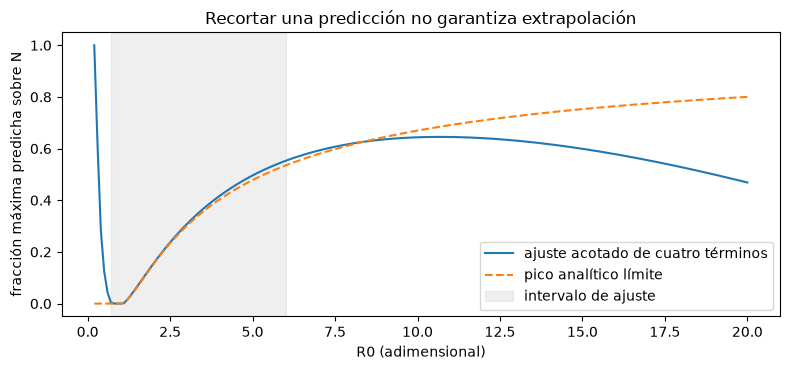

In [9]:
# Cumplir límites puede coexistir con extrapolación implausible fuera del ajuste.
outside_grid = np.linspace(0.2, 20, 199)
outside_prediction = [train.predict(model, value) for value in outside_grid]
outside_baseline = [peak_frac(value) for value in outside_grid]
for value in (0.2, 1.0, 6.0, 10.0, 20.0):
    print(f"R0={value:4.1f}, fit={train.predict(model, value):.5f}, baseline={peak_frac(value):.5f}")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(outside_grid, outside_prediction, label="ajuste acotado de cuatro términos")
ax.plot(outside_grid, outside_baseline, "--", label="pico analítico límite")
ax.axvspan(min(train_r0), max(train_r0), alpha=0.12, color="grey", label="intervalo de ajuste")
ax.set_xlabel("R0 (adimensional)")
ax.set_ylabel("fracción máxima predicha sobre N")
ax.set_title("Recortar una predicción no garantiza extrapolación")
ax.legend()
fig.tight_layout()
plt.show()

El predictor permanece dentro del intervalo legal porque su implementación recorta la expresión ajustada. Aun así, la extrapolación puede aplanarse o caer fuera del intervalo respaldado, mientras el pico analítico límite crece con la razón reproductiva. La figura distingue cumplimiento del rango numérico de plausibilidad científica. Ni el recorte ni un modelo válido de cuatro coeficientes proporcionan monotonía, calibración o intervalos predictivos. Las razones grandes son sondeos educativos, no casos operacionales nuevos admitidos; el contrato CSV advertiría razones suficientemente extremas aunque aceptara los rangos elementales de parámetros.

### Úsalo con tus propios datos

Prepara un CSV con case_id, beta, gamma, N, I0 y days entero positivo explícito. Preprocesa y examina rechazos y advertencias antes de extraer características. No supongas rechazo estricto del horizonte opcional: el lector actual lo convierte, usa el predeterminado cuando falla la conversión y recorta valores no positivos. Quien importe debe revisar si ese comportamiento heredado coincide con sus unidades previstas. Separa puntos antes de llamar a `train.run(training_params, external_models_dir)`; nunca ajustes sobre las observaciones que luego llamarás reservadas. Conserva el modelo devuelto o léelo con `load_released`, y usa `evaluate.run(bundle, holdout_params)` sobre insumos reservados independientemente.

La etapa de exportación consume caso, parámetros aceptados, resultado completo, semilla, run_ms medido del motor, advertencias de admisión, métricas reservadas, procedencia del modelo y límites esperados. Escribe traza compacta y manifiesto en directorios derived/manifests explícitos. Los arreglos de la traza se reducen y redondean para mostrarlos; el resumen proviene del resultado completo, así que recalcular el máximo de la traza puede perder el pico realmente muestreado. El manifiesto conecta identificador, versión del motor, ruta relativa y tamaño, parámetros, decisión de ejecución, métricas y `models["surrogate-model"]`. Esta lección explica ese límite sin ejecutar la orquestación canónica ni fabricar una medición de tiempo.

La disponibilidad distingue un modelo ausente o inválido, un modelo publicado que responde durante un entrenamiento más nuevo y una generación cuyas métricas todavía usaron la base. Estado y procedencia deben acompañar la predicción, no inferirse de que exista un archivo. La API inactiva expone los mismos límites documentales mediante respuestas explícitas no disponibles; una ruta GET declarada no prueba un servicio activo. Amplía el contrato de entrada y reentrena solamente después de definir horizonte y población de condiciones iniciales. Una aplicación epidémica real exigiría además observaciones adecuadas, validación científica e incertidumbre más allá de esta plantilla.

## Resultados

**Respuesta:** Con R0 = 2,75 el predictor ajustado devuelve 0,27345 para todas las combinaciones iniciales y temporales, incluyendo el caso exactamente sin semilla cuyo pico real del motor es cero. El mapa separa esos resultados: R0 solo no identifica cualquier pico solicitado. El ajuste temporal usa cuatro coeficientes y se evalúa sobre seis puntos diferentes reservados; RMSE y R cuadrado impresos describen solamente esa población construida explícitamente. Difieren de las métricas publicadas sobre veinte puntos y no aportan calificación clínica o predictiva.

Calidad predictiva, rango contractual y procedencia responden preguntas distintas. Un modelo válido puede extrapolar de forma implausible; un respaldo puede mantener la interfaz con otros supuestos iniciales; un ajuste finito preciso puede omitir un pico futuro. Conservar estas diferencias es el valor práctico de etapas y ranura del modelo.

## Resumen

- La etapa real de características conserva campos que el sustituto escalar descarta.
- Entrenamiento, predicción y evaluación usan APIs existentes, con ajuste temporal separado del modelo publicado.
- Insumos reservados diferentes exponen límites de interpolación sin demostrar validez externa.
- Un R0 idéntico puede corresponder a máximos finitos distintos si cambia el estado inicial.
- Forma del modelo, rango legal, procedencia y adecuación científica requieren interpretaciones separadas.

## Referencias

- Kermack y McKendrick (1927), sistema SIR gobernante: https://doi.org/10.1098/rspa.1927.0118
- Hethcote (2000), supuestos y umbrales SIR: https://doi.org/10.1137/S0036144500371907
- Miller (2012), condiciones e interpretación del tamaño final: https://doi.org/10.1007/s11538-012-9749-6
- API primaria de mínimos cuadrados de NumPy: https://numpy.org/doc/2.4/reference/generated/numpy.linalg.lstsq.html
- Entrenador real de base fija, sin afirmar que la base sea un óptimo de investigación: https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE/blob/0190bf8/data-pipeline/pipeline/stages/train.py